In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '/content/drive/MyDrive/RadarGestureEdgeAI')
import radar_utils as ru
importlib.reload(ru)

X, y, meta = ru.load_data()
print("Ready:", X.shape)

Mounted at /content/drive
Ready: (9593, 90, 189, 3)


In [2]:
def clutter_mean(rec):
    """Subtract each range bin's average over time. rec: (frames, bins, channels)"""
    return rec - rec.mean(axis=0, keepdims=True)

def clutter_loopback(rec, alpha=0.9):
    """Causal running-background subtraction (real-time friendly)."""
    out = np.empty_like(rec)
    background = rec[0].copy()
    for n in range(rec.shape[0]):
        background = alpha * background + (1 - alpha) * rec[n]
        out[n] = rec[n] - background
    return out

print("Clutter removal functions ready.")

Clutter removal functions ready.


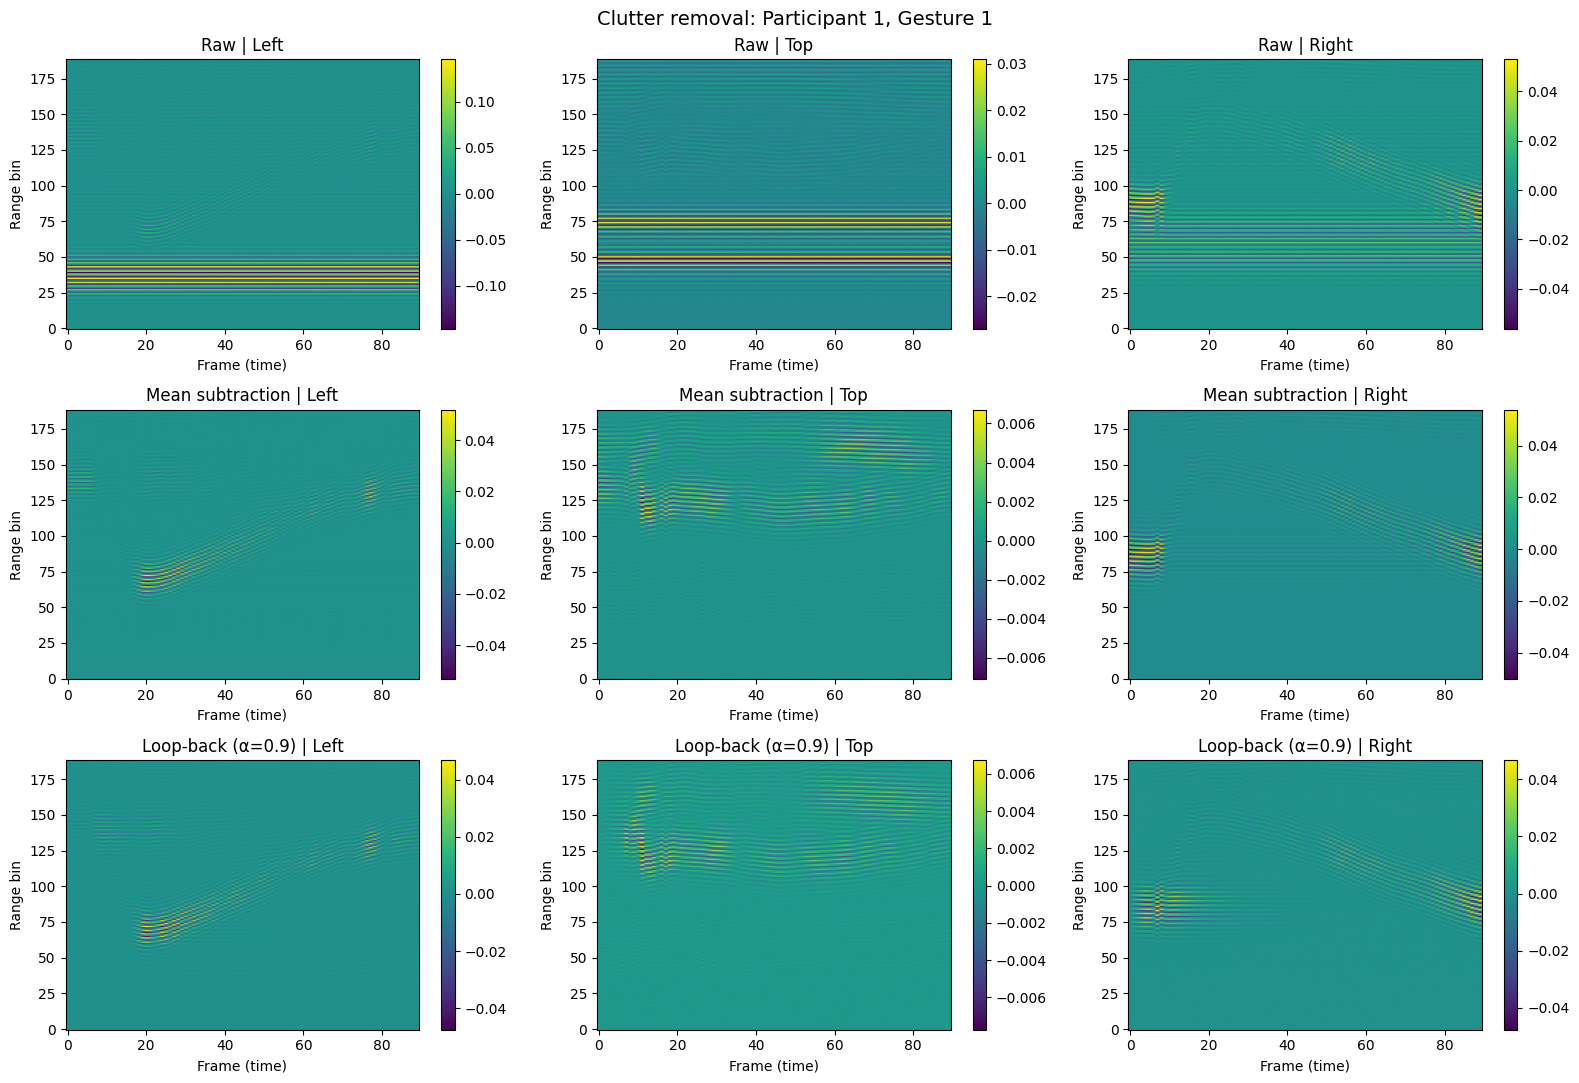

STATIC CLUTTER ENERGY (fraction of raw energy removed)
Left  | mean-sub removed:  97.94% | loop-back removed:  98.23%
Top   | mean-sub removed:  98.23% | loop-back removed:  98.63%
Right | mean-sub removed:  67.90% | loop-back removed:  73.57%


In [3]:
# Participant 1, Gesture 1, Recording 10
i = meta.index[(meta.participant_id == 1) & (meta.gesture_id == 1) &
               (meta.recording_number == 10)][0]
raw = np.asarray(X[i], dtype=np.float32)

versions = {
    'Raw': raw,
    'Mean subtraction': clutter_mean(raw),
    'Loop-back (α=0.9)': clutter_loopback(raw),
}

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for r, (name, data) in enumerate(versions.items()):
    for c, ch in enumerate(ru.CHANNELS):
        im = axes[r, c].imshow(data[:, :, c].T, aspect='auto',
                               origin='lower', cmap='viridis')
        axes[r, c].set_title(f'{name} | {ch}')
        axes[r, c].set_xlabel('Frame (time)')
        axes[r, c].set_ylabel('Range bin')
        plt.colorbar(im, ax=axes[r, c])

plt.suptitle('Clutter removal: Participant 1, Gesture 1', fontsize=14)
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_clutter_removal.png', dpi=200)
plt.show()

# Signal energy ka kitna hissa static clutter tha?
print("STATIC CLUTTER ENERGY (fraction of raw energy removed)")
for c, ch in enumerate(ru.CHANNELS):
    e_raw = np.sum(raw[:, :, c] ** 2)
    e_mean = np.sum(versions['Mean subtraction'][:, :, c] ** 2)
    e_loop = np.sum(versions['Loop-back (α=0.9)'][:, :, c] ** 2)
    print(f"{ch:5s} | mean-sub removed: {100*(1 - e_mean/e_raw):6.2f}%"
          f" | loop-back removed: {100*(1 - e_loop/e_raw):6.2f}%")

In [4]:
%%writefile -a /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


# ================= Phase 2: Signal processing =================

def clutter_mean_batch(batch):
    """batch: (B, frames, bins, channels). Subtract each bin's mean over time."""
    return batch - batch.mean(axis=1, keepdims=True)


def clutter_loopback_batch(batch, alpha=0.9):
    """Causal running-background subtraction, vectorised over the batch."""
    out = np.empty_like(batch)
    background = batch[:, 0].copy()
    for n in range(batch.shape[1]):
        background = alpha * background + (1 - alpha) * batch[:, n]
        out[:, n] = batch[:, n] - background
    return out


def block_features(batch):
    """(B, 90, 189, 3) -> (B, 729): mean, std, abs-mean of 9x9 time-range blocks."""
    blocks = batch.reshape(-1, 9, 10, 9, 21, 3)
    return np.concatenate([
        blocks.mean(axis=(2, 4)).reshape(len(batch), -1),
        blocks.std(axis=(2, 4)).reshape(len(batch), -1),
        np.abs(blocks).mean(axis=(2, 4)).reshape(len(batch), -1),
    ], axis=1).astype(np.float32)


def compute_features(X, transform=None, chunk=256):
    """Apply optional preprocessing per batch, then extract block features."""
    F = np.zeros((len(X), 729), dtype=np.float32)
    for s in range(0, len(X), chunk):
        batch = np.asarray(X[s:s + chunk], dtype=np.float32)
        if transform is not None:
            batch = transform(batch)
        F[s:s + chunk] = block_features(batch)
    return F


def run_loso_baselines(F, y, meta, tag, verbose=True):
    """LogReg + RandomForest on all 8 LOSO folds. Saves results to Drive."""
    import time
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier

    set_seed()
    rows, preds = [], []
    for f in loso_folds(meta):
        tr, te = f['train_idx'], f['test_idx']
        models = {
            'LogReg': make_pipeline(
                StandardScaler(),
                LogisticRegression(max_iter=2000, C=1.0, random_state=SEED)),
            'RandomForest': RandomForestClassifier(
                n_estimators=200, max_features='sqrt', min_samples_leaf=2,
                random_state=SEED, n_jobs=-1),
        }
        for name, model in models.items():
            t0 = time.time()
            model.fit(F[tr], y[tr])
            p = model.predict(F[te])
            m = evaluate(y[te], p)
            rows.append({'model': name, 'fold': f['fold'],
                         'test_subject': f['test_subject'], **m})
            preds.append(pd.DataFrame({'model': name, 'fold': f['fold'], 'idx': te,
                                       'y_true': y[te], 'y_pred': p}))
            if verbose:
                print(f"[{tag}] Fold {f['fold']} (S{f['test_subject']}) | {name:12s} | "
                      f"acc={m['accuracy']:.3f} | F1={m['macro_f1']:.3f} | "
                      f"{time.time() - t0:.0f}s")
    results = pd.DataFrame(rows)
    save_results(results, f'loso_baselines_{tag}')
    save_results(pd.concat(preds), f'loso_baselines_{tag}_predictions')
    return results

Appending to /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


In [5]:
importlib.reload(ru)
from functools import partial

methods = {
    'meansub':  ru.clutter_mean_batch,
    'loopback': partial(ru.clutter_loopback_batch, alpha=0.9),
}

feats = {}
for tag, fn in methods.items():
    path = ru.PROJECT / 'processed' / f'features_blocks_{tag}.npy'
    if path.exists():
        feats[tag] = np.load(path)
        print(f"{tag}: loaded from Drive")
    else:
        feats[tag] = ru.compute_features(X, transform=fn)
        np.save(path, feats[tag])
        print(f"{tag}: computed and saved")
    print(f"   shape={feats[tag].shape} | finite={np.isfinite(feats[tag]).all()}")

meansub: computed and saved
   shape=(9593, 729) | finite=True
loopback: computed and saved
   shape=(9593, 729) | finite=True


In [6]:
results = {}
for tag in ['meansub', 'loopback']:
    results[tag] = ru.run_loso_baselines(feats[tag], y, meta, tag)
    print()

[meansub] Fold 1 (S1) | LogReg       | acc=0.913 | F1=0.913 | 6s
[meansub] Fold 1 (S1) | RandomForest | acc=0.972 | F1=0.971 | 46s
[meansub] Fold 2 (S2) | LogReg       | acc=0.885 | F1=0.884 | 3s
[meansub] Fold 2 (S2) | RandomForest | acc=0.911 | F1=0.909 | 46s
[meansub] Fold 3 (S3) | LogReg       | acc=0.804 | F1=0.794 | 2s
[meansub] Fold 3 (S3) | RandomForest | acc=0.863 | F1=0.833 | 44s
[meansub] Fold 4 (S4) | LogReg       | acc=0.768 | F1=0.747 | 3s
[meansub] Fold 4 (S4) | RandomForest | acc=0.829 | F1=0.802 | 45s
[meansub] Fold 5 (S5) | LogReg       | acc=0.917 | F1=0.917 | 2s
[meansub] Fold 5 (S5) | RandomForest | acc=0.959 | F1=0.959 | 43s
[meansub] Fold 6 (S6) | LogReg       | acc=0.710 | F1=0.704 | 3s
[meansub] Fold 6 (S6) | RandomForest | acc=0.800 | F1=0.765 | 42s
[meansub] Fold 7 (S7) | LogReg       | acc=0.853 | F1=0.847 | 5s
[meansub] Fold 7 (S7) | RandomForest | acc=0.958 | F1=0.957 | 44s
[meansub] Fold 8 (S8) | LogReg       | acc=0.888 | F1=0.882 | 5s
[meansub] Fold 8 (

In [7]:
names = {'raw': 'Raw', 'meansub': 'Mean subtraction', 'loopback': 'Loop-back'}

frames = []
for tag, label in names.items():
    d = pd.read_csv(ru.PROJECT / 'results' / f'loso_baselines_{tag}.csv')
    d['preprocessing'] = label
    frames.append(d)
allr = pd.concat(frames, ignore_index=True)

print("===== PREPROCESSING COMPARISON (LOSO, %, mean ± std) =====")
summary = (allr.groupby(['model', 'preprocessing'], sort=False)
               [['accuracy', 'macro_f1']].agg(['mean', 'std']) * 100).round(1)
print(summary)

print("\n===== LogReg macro-F1 per test subject (%) =====")
per_subject = (allr[allr.model == 'LogReg']
               .pivot(index='test_subject', columns='preprocessing', values='macro_f1') * 100)
print(per_subject[list(names.values())].round(1))

ru.save_results(allr, 'table_preprocessing_comparison')


===== PREPROCESSING COMPARISON (LOSO, %, mean ± std) =====
                              accuracy      macro_f1     
                                  mean  std     mean  std
model        preprocessing                               
LogReg       Raw                  78.2  7.7     76.5  8.6
RandomForest Raw                  73.9  7.6     70.6  9.0
LogReg       Mean subtraction     84.2  7.5     83.6  8.0
RandomForest Mean subtraction     90.5  6.6     89.3  8.1
LogReg       Loop-back            85.4  7.7     84.8  7.9
RandomForest Loop-back            91.1  6.2     89.9  7.7

===== LogReg macro-F1 per test subject (%) =====
preprocessing   Raw  Mean subtraction  Loop-back
test_subject                                    
1              78.4              91.3       93.0
2              79.0              88.4       89.8
3              67.7              79.4       79.3
4              73.5              74.7       78.4
5              90.0              91.7       92.0
6              65.9       

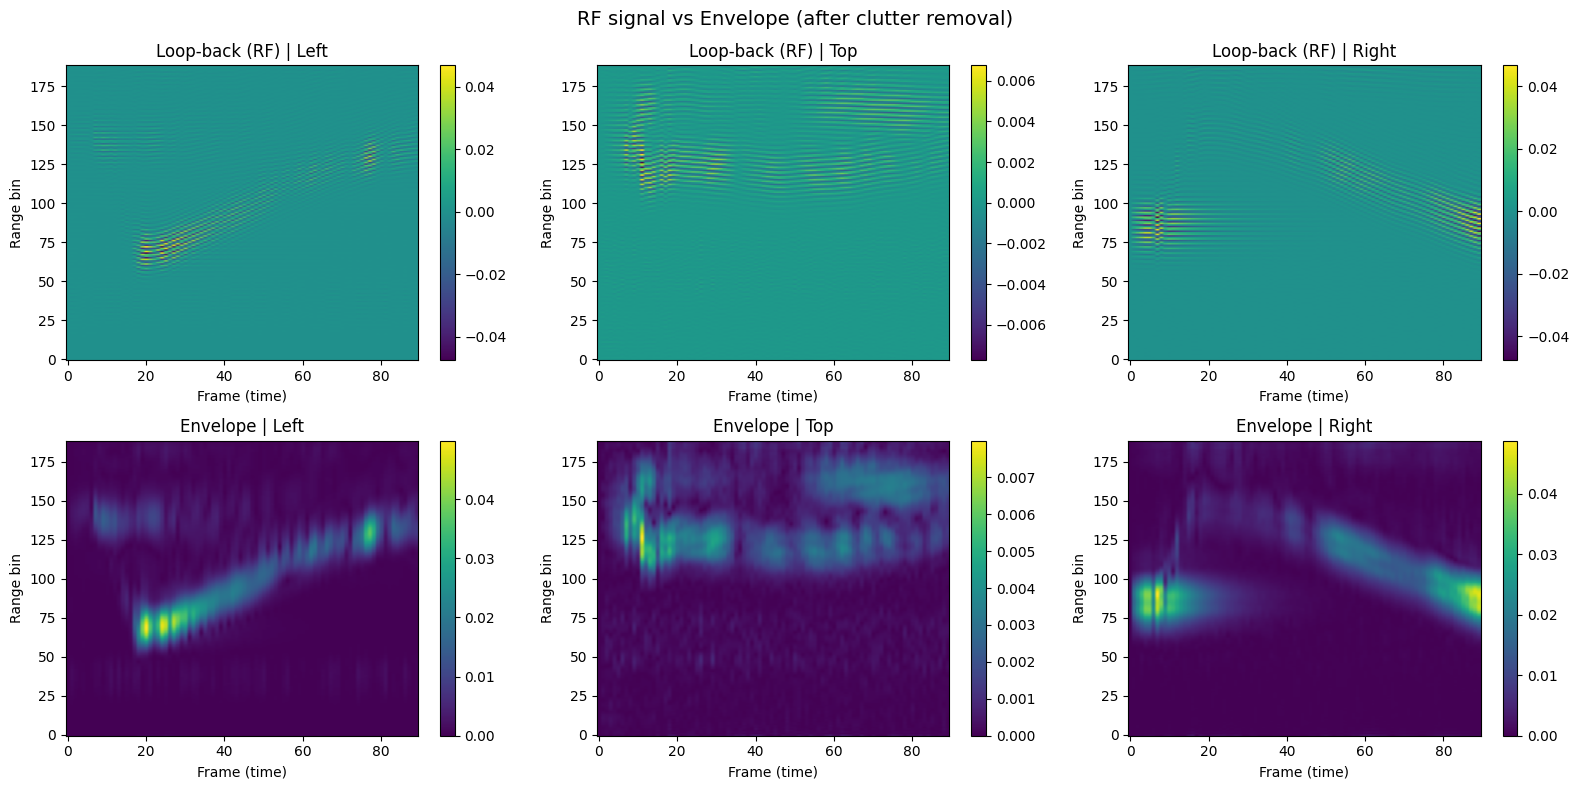

In [8]:
from scipy.signal import hilbert

def envelope_batch(batch):
    """RF signal -> envelope (signal strength), along the range axis."""
    return np.abs(hilbert(batch, axis=2)).astype(np.float32)

# Same recording as Step 2.1 (Participant 1, Gesture 1, Recording 10)
i = meta.index[(meta.participant_id == 1) & (meta.gesture_id == 1) &
               (meta.recording_number == 10)][0]
rec = np.asarray(X[i:i+1], dtype=np.float32)          # (1, 90, 189, 3)
clean = ru.clutter_loopback_batch(rec)
env = envelope_batch(clean)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for c, ch in enumerate(ru.CHANNELS):
    for r, (name, data) in enumerate([('Loop-back (RF)', clean), ('Envelope', env)]):
        im = axes[r, c].imshow(data[0, :, :, c].T, aspect='auto',
                               origin='lower', cmap='viridis')
        axes[r, c].set_title(f'{name} | {ch}')
        axes[r, c].set_xlabel('Frame (time)')
        axes[r, c].set_ylabel('Range bin')
        plt.colorbar(im, ax=axes[r, c])

plt.suptitle('RF signal vs Envelope (after clutter removal)', fontsize=14)
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_envelope.png', dpi=200)
plt.show()

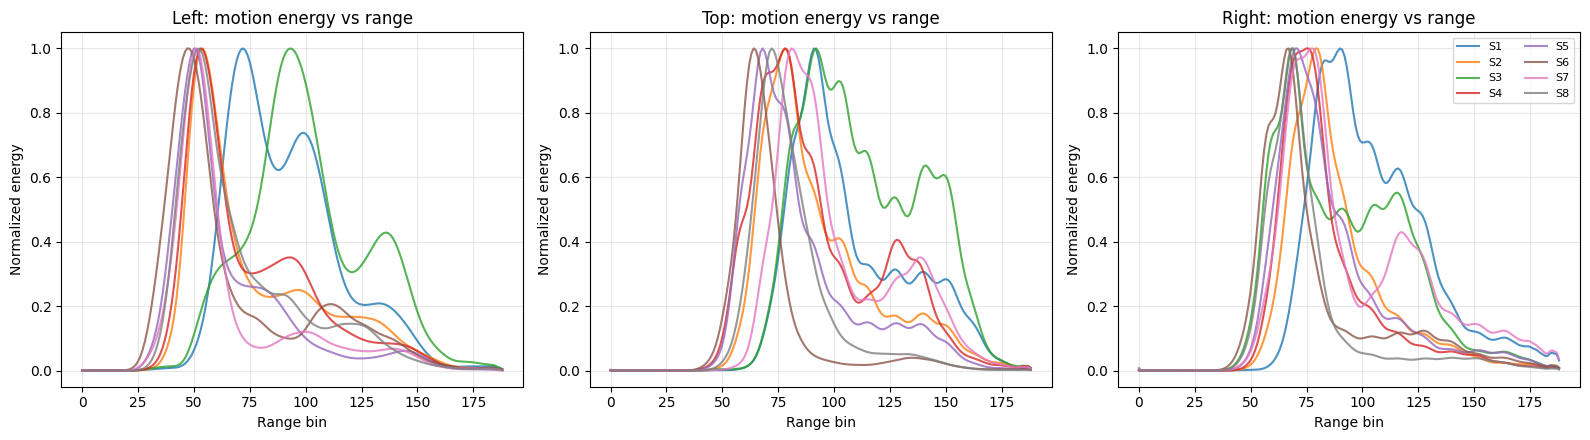

RANGE BINS CONTAINING 95% OF MOTION ENERGY
Left : bins  37 – 147  (111 bins)
Top  : bins  56 – 156  (101 bins)
Right: bins  54 – 161  (108 bins)

Combined (all channels): bins 37 – 161


In [9]:
rng = np.random.default_rng(ru.SEED)
profiles = {}

for s in ru.SUBJECTS:
    pool = np.flatnonzero((meta.participant_id == s).to_numpy() &
                          ~meta.is_duplicate.to_numpy())
    idx = np.sort(rng.choice(pool, 150, replace=False))   # 150 random recordings
    b = np.asarray(X[idx], dtype=np.float32)
    e = envelope_batch(ru.clutter_loopback_batch(b))
    profiles[s] = (e ** 2).mean(axis=(0, 1))               # motion energy per bin: (189, 3)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for c, ch in enumerate(ru.CHANNELS):
    for s in ru.SUBJECTS:
        p = profiles[s][:, c]
        axes[c].plot(p / p.max(), label=f'S{s}', alpha=0.8)
    axes[c].set_title(f'{ch}: motion energy vs range')
    axes[c].set_xlabel('Range bin')
    axes[c].set_ylabel('Normalized energy')
    axes[c].grid(True, alpha=0.3)
axes[2].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_range_energy_profile.png', dpi=200)
plt.show()

# Which bins hold 95% of the motion energy? (2.5% to 97.5% of cumulative energy)
print("RANGE BINS CONTAINING 95% OF MOTION ENERGY")
lows, highs = [], []
for c, ch in enumerate(ru.CHANNELS):
    avg = np.mean([profiles[s][:, c] / profiles[s][:, c].sum() for s in ru.SUBJECTS], axis=0)
    cum = np.cumsum(avg)
    lo = int(np.searchsorted(cum, 0.025))
    hi = int(np.searchsorted(cum, 0.975))
    lows.append(lo); highs.append(hi)
    print(f"{ch:5s}: bins {lo:3d} – {hi:3d}  ({hi - lo + 1} bins)")
print(f"\nCombined (all channels): bins {min(lows)} – {max(highs)}")

In [10]:
%%writefile -a /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


# ================= Step 2.4: Envelope + compact representation =================
RANGE_CROP = (34, 162)   # 128 bins containing ~95% of motion energy (all subjects)
RANGE_POOL = 4           # 128 -> 32 range cells


def envelope_batch(batch):
    """RF signal -> envelope along the range axis."""
    from scipy.signal import hilbert
    return np.abs(hilbert(batch, axis=2)).astype(np.float32)


def make_compact(batch, alpha=0.9, crop=RANGE_CROP, pool=RANGE_POOL):
    """Raw RF (B, 90, 189, 3) -> compact envelope (B, 90, 128/pool, 3)."""
    x = clutter_loopback_batch(batch, alpha=alpha)
    x = envelope_batch(x)
    x = x[:, :, crop[0]:crop[1], :]
    B, T, R, C = x.shape
    return x.reshape(B, T, R // pool, pool, C).mean(axis=3).astype(np.float32)


def build_compact_dataset(X, out_path, chunk=256, **kwargs):
    """Apply make_compact to the whole dataset, writing to a .npy file."""
    first = make_compact(np.asarray(X[:1], dtype=np.float32), **kwargs)
    Xc = np.lib.format.open_memmap(out_path, mode='w+', dtype=np.float32,
                                   shape=(len(X),) + first.shape[1:])
    for s in range(0, len(X), chunk):
        Xc[s:s + chunk] = make_compact(np.asarray(X[s:s + chunk], dtype=np.float32), **kwargs)
    Xc.flush()
    return Xc


def compact_block_features(batch, t_blocks=9, r_blocks=8):
    """(B, 90, 32, 3) -> (B, 648): mean, std, max of 9x8 time-range blocks."""
    B, T, R, C = batch.shape
    blocks = batch.reshape(B, t_blocks, T // t_blocks, r_blocks, R // r_blocks, C)
    return np.concatenate([
        blocks.mean(axis=(2, 4)).reshape(B, -1),
        blocks.std(axis=(2, 4)).reshape(B, -1),
        blocks.max(axis=(2, 4)).reshape(B, -1),
    ], axis=1).astype(np.float32)

Appending to /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


Built compact dataset and saved to Drive.
Compact shape: (9593, 90, 32, 3) | finite: True
Size reduction: 51030 -> 8640 values per recording (5.9x smaller)


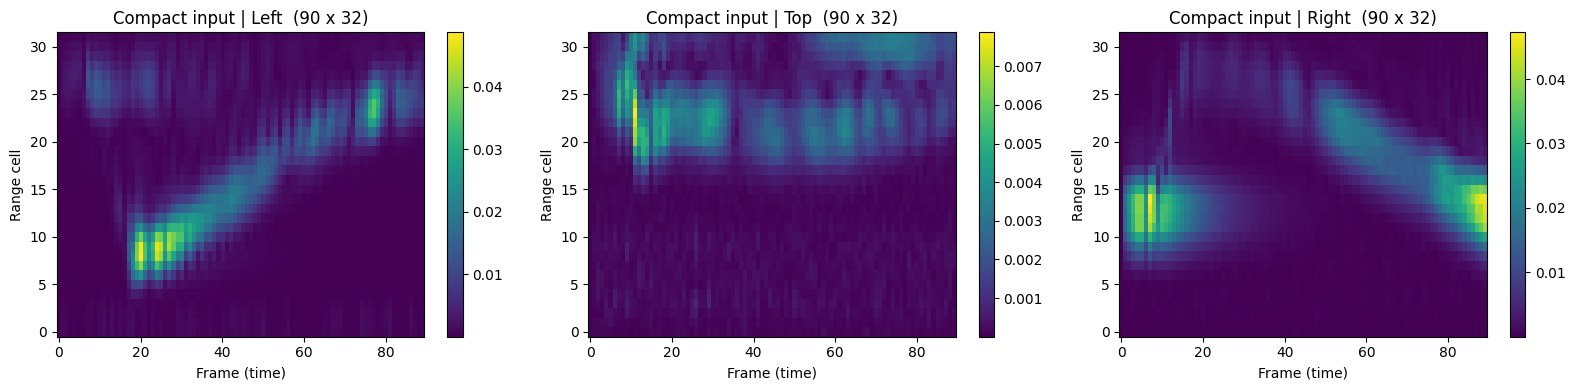

In [11]:
importlib.reload(ru)
import shutil

local_path = ru.LOCAL / 'X_compact.npy'
drive_path = ru.PROJECT / 'processed' / 'X_compact.npy'

if drive_path.exists():
    if not local_path.exists():
        shutil.copy2(drive_path, local_path)
    print("Loaded compact dataset from Drive.")
else:
    ru.build_compact_dataset(X, local_path)
    shutil.copy2(local_path, drive_path)
    print("Built compact dataset and saved to Drive.")

Xc = np.load(local_path, mmap_mode='r')
print("Compact shape:", Xc.shape, "| finite:", np.isfinite(Xc).all())
print(f"Size reduction: {X[0].size} -> {Xc[0].size} values per recording "
      f"({X[0].size / Xc[0].size:.1f}x smaller)")

# Same recording as before: what the model will actually see
i = meta.index[(meta.participant_id == 1) & (meta.gesture_id == 1) &
               (meta.recording_number == 10)][0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for c, ch in enumerate(ru.CHANNELS):
    im = axes[c].imshow(Xc[i, :, :, c].T, aspect='auto', origin='lower', cmap='viridis')
    axes[c].set_title(f'Compact input | {ch}  (90 x 32)')
    axes[c].set_xlabel('Frame (time)')
    axes[c].set_ylabel('Range cell')
    plt.colorbar(im, ax=axes[c])
plt.tight_layout()
plt.savefig(ru.PROJECT / 'figures' / 'fig_compact_input.png', dpi=200)
plt.show()

In [12]:
Fc_path = ru.PROJECT / 'processed' / 'features_blocks_compact.npy'
if Fc_path.exists():
    Fc = np.load(Fc_path)
else:
    Fc = ru.compact_block_features(np.asarray(Xc))
    np.save(Fc_path, Fc)
print("Compact features:", Fc.shape)

ru.run_loso_baselines(Fc, y, meta, 'compact')

# Comparison of all preprocessing versions
names = {'raw': 'Raw', 'meansub': 'Mean subtraction',
         'loopback': 'Loop-back', 'compact': 'Compact envelope'}
frames = []
for tag, label in names.items():
    d = pd.read_csv(ru.PROJECT / 'results' / f'loso_baselines_{tag}.csv')
    d['preprocessing'] = label
    frames.append(d)
allr = pd.concat(frames, ignore_index=True)

print("\n===== PREPROCESSING COMPARISON (LOSO, %, mean ± std) =====")
print((allr.groupby(['model', 'preprocessing'], sort=False)
           [['accuracy', 'macro_f1']].agg(['mean', 'std']) * 100).round(1))

print("\n===== Random Forest macro-F1 per test subject (%) =====")
rf = allr[allr.model == 'RandomForest'].pivot(index='test_subject',
                                              columns='preprocessing', values='macro_f1') * 100
print(rf[list(names.values())].round(1))

ru.save_results(allr, 'table_preprocessing_comparison')

Compact features: (9593, 648)
[compact] Fold 1 (S1) | LogReg       | acc=0.940 | F1=0.939 | 4s
[compact] Fold 1 (S1) | RandomForest | acc=0.985 | F1=0.985 | 49s
[compact] Fold 2 (S2) | LogReg       | acc=0.895 | F1=0.890 | 5s
[compact] Fold 2 (S2) | RandomForest | acc=0.922 | F1=0.921 | 41s
[compact] Fold 3 (S3) | LogReg       | acc=0.831 | F1=0.815 | 2s
[compact] Fold 3 (S3) | RandomForest | acc=0.862 | F1=0.829 | 43s
[compact] Fold 4 (S4) | LogReg       | acc=0.771 | F1=0.754 | 3s
[compact] Fold 4 (S4) | RandomForest | acc=0.862 | F1=0.850 | 42s
[compact] Fold 5 (S5) | LogReg       | acc=0.938 | F1=0.938 | 2s
[compact] Fold 5 (S5) | RandomForest | acc=0.975 | F1=0.975 | 37s
[compact] Fold 6 (S6) | LogReg       | acc=0.713 | F1=0.676 | 1s
[compact] Fold 6 (S6) | RandomForest | acc=0.791 | F1=0.751 | 40s
[compact] Fold 7 (S7) | LogReg       | acc=0.878 | F1=0.870 | 4s
[compact] Fold 7 (S7) | RandomForest | acc=0.933 | F1=0.926 | 42s
[compact] Fold 8 (S8) | LogReg       | acc=0.876 | F1